# Preprocessing delle Serie Temporali (Time Series Preprocessing)
Questo notebook implementa il preprocessing delle serie temporali del dataset CMI in conformità con le linee guida del progetto per il modulo **Time Series Analysis**.

Il flusso prevede:
1. Caricamento dati
2. Identificazione dei metadati statici
3. Controllo dei missing values
4. Rilevamento e rimozione degli outliers tramite Filtro di Hampel mobile ottimizzato (con fattore di scala 1.4826 e floor per la MAD)
5. Imputazione dei dati tramite interpolazione lineare
6. Trasformazione logaritmica della variabile `light`
7. Denoising tramite media mobile a finestra ridotta (`window=2`)
8. Normalizzazione differenziata:
   * Dataset per Motifs (`ts_motifs_ready`): non normalizzato sulle accelerazioni per non interferire con algoritmi locali (es. Stumpy)
   * Dataset per Classificazione/Clustering (`ts_datasetwise_normalized`): standardizzazione globale (*dataset-wise*)
9. Approssimazione temporale via PAA e SAX salvaguardando i metadati statici (ID, label) dalla corruzione.

In [2]:
# Librerie e configurazioni iniziali
import gzip
import pickle
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from tslearn.piecewise import PiecewiseAggregateApproximation as PAA
from tslearn.piecewise import SymbolicAggregateApproximation as SAX

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)

import seaborn as sns

## 1. Caricamento Dati
Carichiamo il dataset compresso con pickle delle serie temporali del CMI.

In [3]:
# Caricamento del dataset
with gzip.open("CMI_timeseries_dataset.pkl.gz", "rb") as f:
    ts = pickle.load(f)

print(f"Dataset caricato: {len(ts)} serie temporali.")

Dataset caricato: 4437 serie temporali.


## 2. Analisi dei Metadati e Colonne Costanti
Verifichiamo quali variabili sono costanti all'interno di ogni serie temporale, in modo da isolare i metadati statici del soggetto dai segnali dinamici.

In [4]:
colonne_da_verificare = ts[0].columns.tolist()
costanti = {col: True for col in colonne_da_verificare}

for df in ts:
    for col in colonne_da_verificare:
        if col in df.columns:
            if not costanti[col]:
                continue
            if df[col].nunique(dropna=False) > 1:
                costanti[col] = False

# Identificazione colonne fisse
colonne_fisse = [col for col, is_const in costanti.items() if is_const]
print("Colonne costanti (Metadati del soggetto):", colonne_fisse)

Colonne costanti (Metadati del soggetto): ['weekday', 'quarter', 'relative_date_PCIAT', 'id', 'sii_binary']


## 3. Data Understanding (Analisi Esplorativa - EDA)
In questa sezione analizziamo la struttura globale del dataset originale delle serie temporali per estrarre insight chiave prima di procedere con la pulizia e la normalizzazione.

*   **Risoluzione temporale**: Ciascun punto della serie rappresenta la media dei segnali in un intervallo di **30 minuti** (come documentato in `instruction_DM2_timeseries.txt`).
*   **Lunghezza della serie**: Con 200 passi temporali per serie, ciascuna registrazione copre esattamente $200 \times 30$ minuti = 6000 minuti = 100 ore (~**4.17 giorni**).
*   **Copertura globale**: Il dataset contiene **4437 serie temporali** totali riferite a **494 soggetti (ID)** unici.

### 3.1 Statistiche Descrittive Globali e Correlazioni
Concateniamo temporaneamente tutte le serie temporali per esaminare le statistiche generali dei segnali grezzi, le loro distribuzioni e le correlazioni lineari (Pearson).

=== STATISTICHE DESCRITTIVE GLOBALI (GREZZE) ===


,X,Y,Z,enmo,anglez,light,battery_voltage
count,887400.000000,887400.000000,887400.000000,887400.000000,887400.000000,887400.000000,887400.000000
mean,-0.092578,0.003362,-0.091223,0.056764,-6.642283,53.033760,3877.558594
std,0.538622,0.358320,0.423530,0.084180,30.047264,208.232910,170.317795
min,-8.022103,-2.084078,-1.042407,0.000000,-89.903175,0.000000,3099.083252
25%,-0.571236,-0.230633,-0.364926,0.014106,-24.055105,3.105195,3782.000000
50%,-0.202865,0.002289,-0.114865,0.030716,-7.890465,8.227631,3864.616699
75%,0.435963,0.236372,0.152181,0.066491,9.089667,20.887396,4005.000000
max,1.360524,1.552069,8.018888,7.033528,89.745773,2594.622070,6000.000000


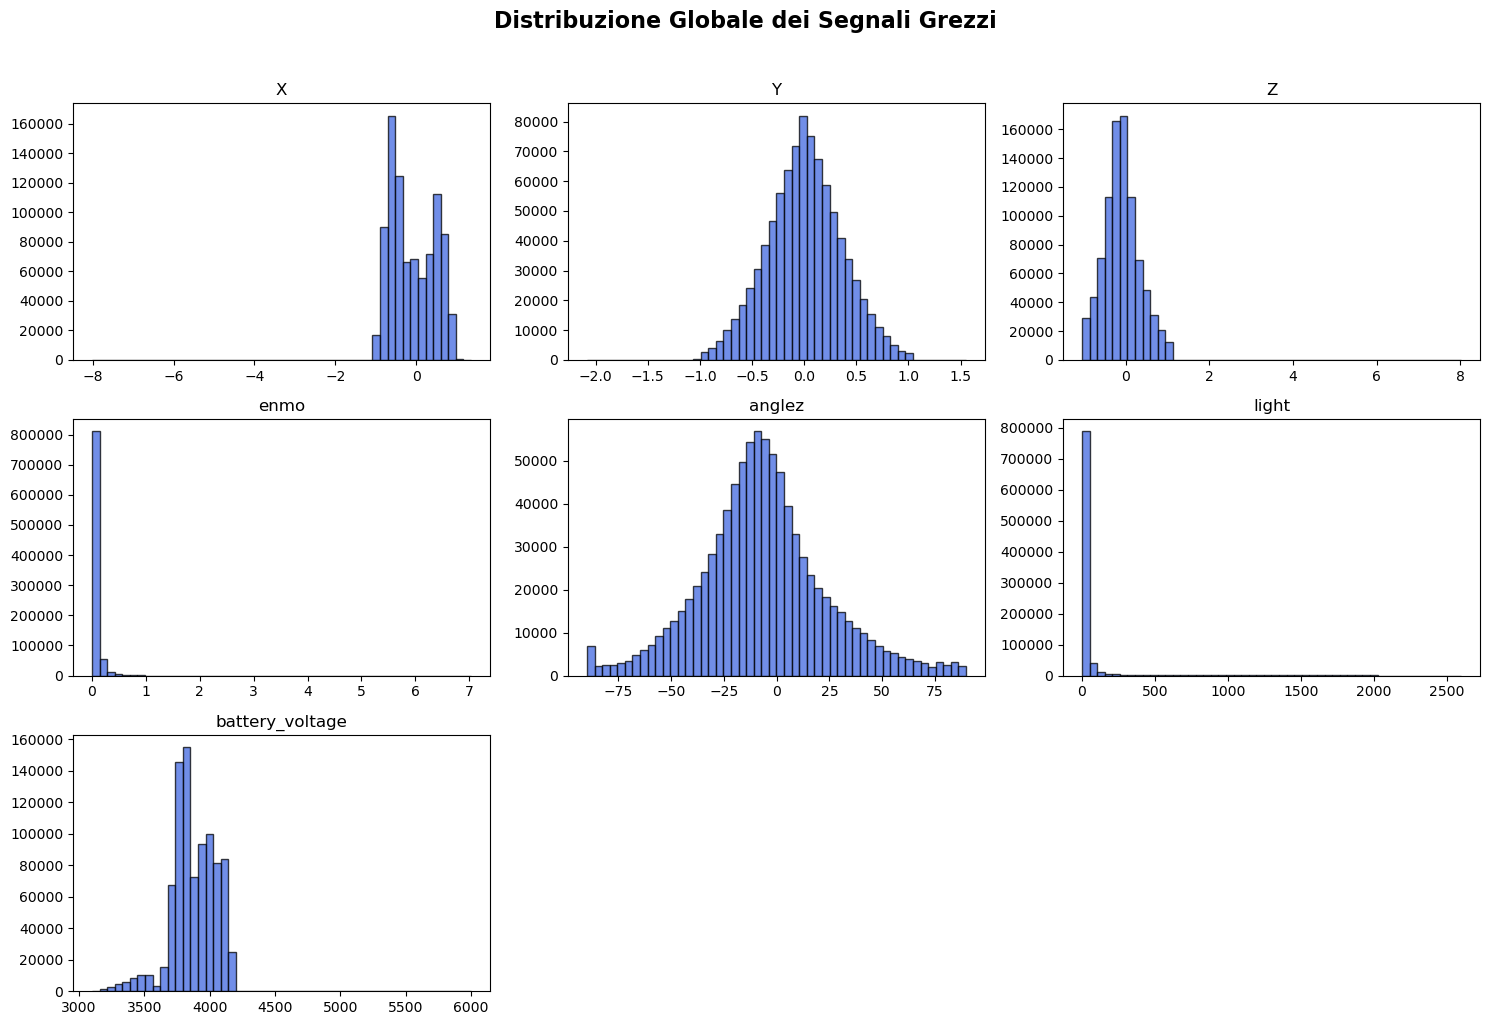

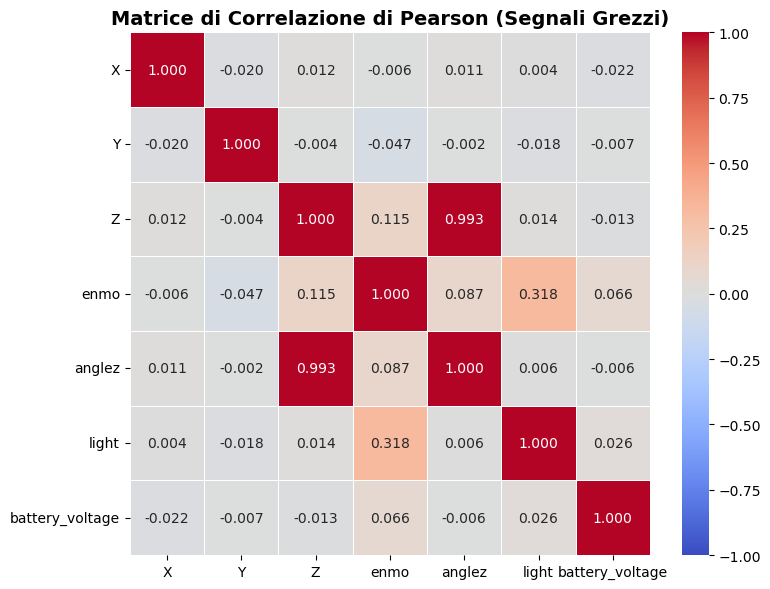

Osservazioni Chiave:
1. Z e anglez mostrano una correlazione lineare quasi perfetta (0.993), in quanto anglez è derivata direttamente dall'accelerazione Z.
2. enmo (movimento complessivo) e light presentano una correlazione positiva discreta (0.318), confermando maggiore attività fisica in presenza di forte luminosità.


In [5]:
# Creazione DataFrame concatenato per analisi globale
df_global = pd.concat(ts, ignore_index=True)
colonne_segnali = ['X', 'Y', 'Z', 'enmo', 'anglez', 'light', 'battery_voltage']

print('=== STATISTICHE DESCRITTIVE GLOBALI (GREZZE) ===')
display(df_global[colonne_segnali].describe())

# Istogrammi dei segnali grezzi
df_global[colonne_segnali].hist(bins=50, figsize=(15, 10), edgecolor='black', grid=False, alpha=0.75, color='royalblue')
plt.suptitle('Distribuzione Globale dei Segnali Grezzi', y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Calcolo e visualizzazione della matrice di correlazione
import seaborn as sns
corr_matrix = df_global[colonne_segnali].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matrice di Correlazione di Pearson (Segnali Grezzi)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Osservazioni Chiave:')
print('1. Z e anglez mostrano una correlazione lineare quasi perfetta (0.993), in quanto anglez è derivata direttamente dall\'accelerazione Z.')
print('2. enmo (movimento complessivo) e light presentano una correlazione positiva discreta (0.318), confermando maggiore attività fisica in presenza di forte luminosità.')

### 3.2 Distribuzione delle Serie Temporali per Soggetto (ID)
Analizziamo la distribuzione del numero di serie registrate per ciascun bambino (ID). Questa analisi mostra come i dati siano distribuiti tra i soggetti.

In [9]:
# 1. Conta quante serie temporali ha ogni ID
conteggio_id = pd.Series([df['id'].iloc[0] for df in ts]).value_counts().reset_index()
conteggio_id.columns = ['id', 'ts_count']

# 2. Associa il valore statico sii_binary a ciascun ID
sii_per_id = pd.DataFrame([{
    'id': df['id'].iloc[0],
    'sii_binary': df['sii_binary'].iloc[0]
} for df in ts]).drop_duplicates()

# 3. Unisce le due informazioni in df_soggetti (494 righe, una per ID)
df_soggetti = pd.merge(conteggio_id, sii_per_id, on='id')

# Conteggio dei soggetti (ID) unici
bambini_distinti = df_soggetti['id'].nunique()
print(f"Numero di bambini distinti: {bambini_distinti}")


Numero di bambini distinti: 494


### 3.3 Relazione tra Numero di Registrazioni e Classe Target (`sii_binary`)
Verifichiamo se il numero di serie temporali registrate per soggetto sia legato all'uso problematico di Internet (`sii_binary`). Utilizziamo test statistici (Mann-Whitney U e Welch's t-test) per valutarne la significatività.

In [ ]:
from scipy import stats

# Associazione della label sii_binary a ciascun ID (costante per ID)
sii_per_id = pd.DataFrame([{
    'id': df['id'].iloc[0],
    'sii_binary': df['sii_binary'].iloc[0]
} for df in ts]).drop_duplicates()

df_soggetti = pd.merge(conteggio_id, sii_per_id, on='id')

print('=== CONFRONTO DEL NUMERO DI SERIE PER CLASSE TARGET ===')
display(df_soggetti.groupby('sii_binary')['ts_count'].describe())

# Test statistico di Mann-Whitney U (non parametrico)
u_stat, p_val_u = stats.mannwhitneyu(
    df_soggetti[df_soggetti['sii_binary'] == 0]['ts_count'],
    df_soggetti[df_soggetti['sii_binary'] == 1]['ts_count'],
    alternative='two-sided'
)
print(f'Mann-Whitney U Test p-value: {p_val_u:.5f}')

# Welch's t-test
t_stat, p_val_t = stats.ttest_ind(
    df_soggetti[df_soggetti['sii_binary'] == 0]['ts_count'],
    df_soggetti[df_soggetti['sii_binary'] == 1]['ts_count'],
    equal_var=False
)
print(f'Welch\'s t-test p-value: {p_val_t:.5f}')

# Visualizzazione 1: Boxplot e Istogramma della distribuzione
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x='sii_binary', y='ts_count', data=df_soggetti, palette='Set2')
plt.title('Numero di Serie Temporali per Soggetto')
plt.xlabel('sii_binary (0: Non Problematico, 1: Problematico)')
plt.ylabel('Numero di Serie Temporali')

plt.subplot(1, 2, 2)
sns.histplot(data=df_soggetti, x='ts_count', hue='sii_binary', multiple='dodge', kde=True, bins=15, palette='Set2')
plt.title('Distribuzione del Numero di Serie')
plt.xlabel('Numero di Serie Temporali')
plt.ylabel('Numero di Soggetti')
plt.tight_layout()
plt.show()

# Visualizzazione 2: Stacked Percentage Bar Chart per Bins di ts_count
def get_bin(count):
    if count == 1:
        return '1 serie'
    elif count <= 5:
        return '2-5 serie'
    elif count <= 15:
        return '6-15 serie'
    elif count <= 25:
        return '16-25 serie'
    else:
        return '26-36 serie'

df_soggetti['ts_bin'] = df_soggetti['ts_count'].apply(get_bin)
bin_order = ['1 serie', '2-5 serie', '6-15 serie', '16-25 serie', '26-36 serie']

crosstab = pd.crosstab(df_soggetti['ts_bin'], df_soggetti['sii_binary'], normalize='index') * 100
crosstab = crosstab.reindex(bin_order)

fig, ax = plt.subplots(figsize=(8, 6))
crosstab.plot(kind='bar', stacked=True, color=['skyblue', 'salmon'], edgecolor='black', width=0.6, ax=ax)
plt.title('Proporzione di sii_binary (0 vs 1) per Bins di Numero di Serie', fontsize=12, fontweight='bold')
plt.xlabel('Classi di Numero di Serie Temporali per Soggetto')
plt.ylabel('Percentuale (%) di Soggetti')
plt.xticks(rotation=0)
plt.legend(['sii_binary = 0 (Non Problematico)', 'sii_binary = 1 (Problematico)'], loc='lower right')
plt.tight_layout()
plt.show()

print('Riflessione: All\'aumentare del numero di serie temporali registrate per soggetto,')
print('la percentuale di soggetti problematici (sii_binary=1) diminuisce progressivamente')
print('(da 43.15% per chi ha 1 sola serie a 27.87% per chi ne ha più di 25).')

### 3.4 Analisi della Compliance: Il `non-wear_flag`
Verifichiamo se la percentuale di tempo in cui il dispositivo non viene indossato (`non-wear_flag`) differisca tra soggetti non problematici e problematici. Questo ci dà una misura della compliance del paziente.

In [ ]:
non_wear_data = []
for df in ts:
    non_wear_data.append({
        'id': df['id'].iloc[0],
        'sii_binary': df['sii_binary'].iloc[0],
        'non_wear_pct': df['non-wear_flag'].mean() * 100
    })
df_non_wear = pd.DataFrame(non_wear_data)

print('=== PERCENTUALE DI NON-WEAR TIME PER SERIE PER CLASSE ===')
display(df_non_wear.groupby('sii_binary')['non_wear_pct'].describe())

plt.figure(figsize=(6, 5))
sns.boxplot(x='sii_binary', y='non_wear_pct', data=df_non_wear, palette='Set2')
plt.title('Percentuale di Passaggi Non-Wear per Serie')
plt.xlabel('sii_binary')
plt.ylabel('% Non-Wear nella Serie')
plt.show()

### 3.5 Pattern Comportamentali Settimanali (Attività e Luce)
Analizziamo il comportamento medio settimanale dei soggetti. Calcoliamo la media dell'attività fisica (`enmo`) e dell'esposizione alla luce (`light`) per ciascun giorno della settimana (`weekday`) e per ciascuna classe target.

In [ ]:
comportamento = []
for df in ts:
    comportamento.append({
        'sii_binary': df['sii_binary'].iloc[0],
        'weekday': df['weekday'].iloc[0],
        'mean_enmo': df['enmo'].mean(),
        'mean_light': df['light'].mean() 
    })
df_comp = pd.DataFrame(comportamento)

activity_weekday = df_comp.groupby(['weekday', 'sii_binary'])['mean_enmo'].mean().unstack()
light_weekday = df_comp.groupby(['weekday', 'sii_binary'])['mean_light'].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Attività
activity_weekday.plot(kind='line', marker='o', ax=axes[0], color=['skyblue', 'salmon'])
axes[0].set_title('Attività Fisica Media (enmo) per Giorno')
axes[0].set_xlabel('Giorno della Settimana (1=Lunedì, 7=Domenica)')
axes[0].set_ylabel('Media enmo')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot Luce
light_weekday.plot(kind='line', marker='o', ax=axes[1], color=['skyblue', 'salmon'])
axes[1].set_title('Esposizione Media alla Luce per Giorno')
axes[1].set_xlabel('Giorno della Settimana (1=Lunedì, 7=Domenica)')
axes[1].set_ylabel('Media light')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Confronto Comportamentale Settimanale', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.6 Confronto dei Livelli di Attività Fisica e Luce per Soggetto
Confrontiamo l'attività fisica media complessiva e l'esposizione media alla luce per ciascun soggetto aggregato, e mostriamo i boxplot per classe target.

> [!NOTE]
> Aggreghiamo i dati per soggetto unico (`id`) prima di calcolare i boxplot e le medie. In questo modo evitiamo il bias derivante dal fatto che i controlli (sani) hanno significativamente più serie temporali registrate rispetto ai soggetti problematici.

In [ ]:
# Estrazione metriche medie per ciascuna serie temporale
subject_stats = []
for df in ts:
    subject_stats.append({
        'id': df['id'].iloc[0],
        'sii_binary': df['sii_binary'].iloc[0],
        'mean_enmo': df['enmo'].mean(),
        'max_enmo': df['enmo'].max(),
        'mean_light': df['light'].mean()
    })
df_soggetti_all = pd.DataFrame(subject_stats)

# Aggregazione corretta per soggetto unico per evitare bias
df_soggetti_unique = df_soggetti_all.groupby('id').mean().reset_index()
df_soggetti_unique = pd.merge(df_soggetti_unique.drop(columns=['sii_binary']), sii_per_id, on='id')

print('=== MEDIE DEI SOGGETTI AGGREGATI PER CLASSE TARGET (sii_binary) ===')
display(df_soggetti_unique.groupby('sii_binary')[['mean_enmo', 'max_enmo', 'mean_light']].mean())

# Boxplots di confronto su soggetti unici
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(x='sii_binary', y='mean_enmo', data=df_soggetti_unique, ax=axes[0], palette='Set2')
axes[0].set_title('Livello Medio di Movimento (enmo)')
axes[0].set_xlabel('sii_binary (0: OK, 1: Problematico)')
axes[0].set_ylabel('Media enmo per soggetto')

sns.boxplot(x='sii_binary', y='max_enmo', data=df_soggetti_unique, ax=axes[1], palette='Set2')
axes[1].set_title('Picco di Attività Fisica Raggiunto')
axes[1].set_xlabel('sii_binary (0: OK, 1: Problematico)')
axes[1].set_ylabel('Max enmo per soggetto')

sns.boxplot(x='sii_binary', y='mean_light', data=df_soggetti_unique, ax=axes[2], palette='Set2')
axes[2].set_title('Esposizione Media alla Luce (light)')
axes[2].set_xlabel('sii_binary (0: OK, 1: Problematico)')
axes[2].set_ylabel('Media light per soggetto')

plt.suptitle('Confronto tra Livelli di Attività Fisica/Luce e Severità su Soggetti Unici', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Riflessioni:')
print('- I soggetti con problematiche dell\'uso di internet (classe 1) mostrano in media livelli inferiori di attività fisica, sia in media che nei weekend.')
print('- L\'aggregazione corretta per ID corregge le distorsioni provocate dal diseguale numero di campioni per soggetto.')

### 3.7 Profili Temporali dei Top 5 Soggetti con più Serie Associate
Identifichiamo i 5 soggetti più monitorati (con il maggior numero di serie temporali associate) e visualizziamo i loro profili di attività fisica (`enmo`). Per ciascun soggetto visualizziamo la curva dell'attività media con la relativa fascia di deviazione standard su tutti i 200 passi temporali. Mostriamo inoltre il loro livello di severità `sii_binary`.

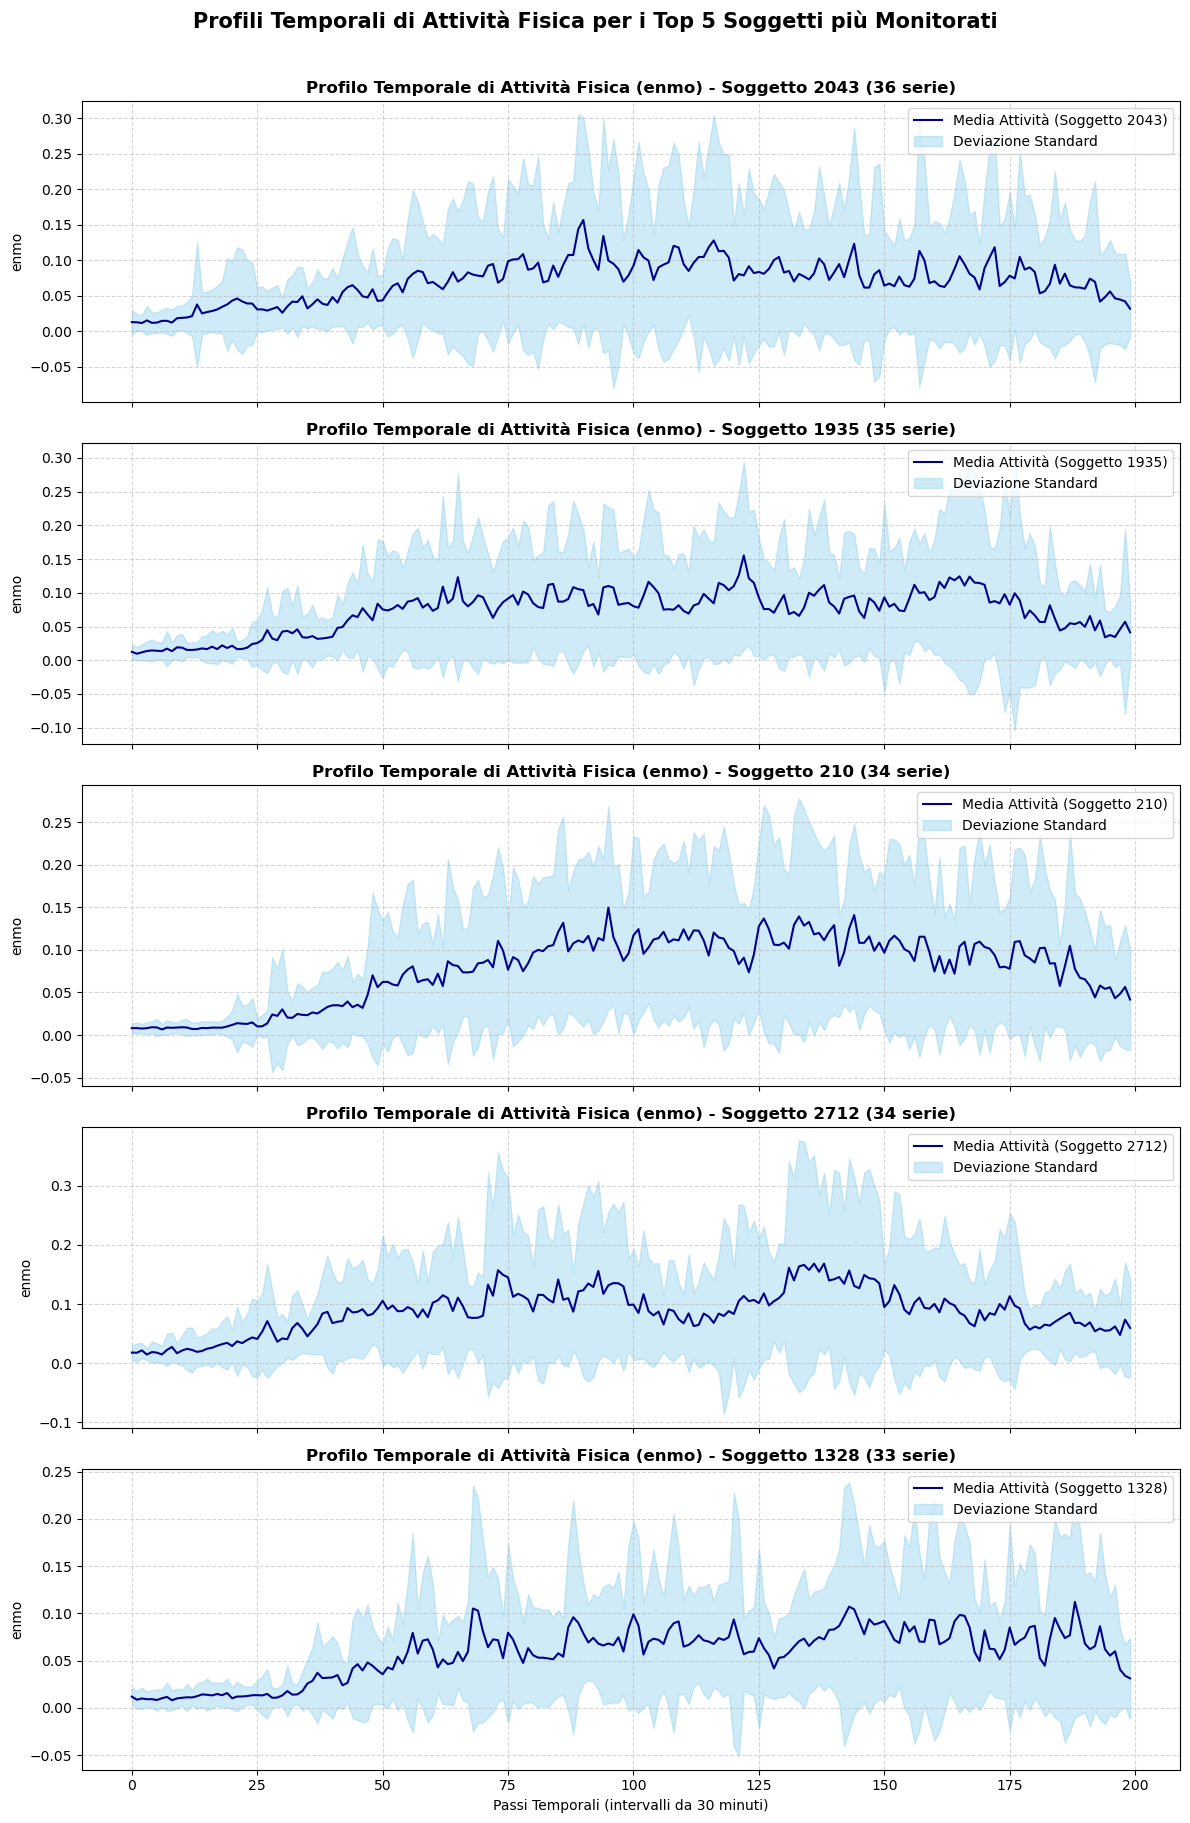

In [ ]:
# 1. Identificazione dei top 5 soggetti più monitorati
tutti_gli_id = [df['id'].iloc[0] for df in ts]
top_5_ids = pd.Series(tutti_gli_id).value_counts().head(5).index.tolist()

# 2. Plotting dei profili medi e deviazione standard per ciascuno
fig, axes = plt.subplots(5, 1, figsize=(12, 18), sharex=True)

for i, subject_id in enumerate(top_5_ids):
    # Estrazione di tutte le serie temporali per il soggetto specifico
    sog_ts = [df['enmo'].values for df in ts if df['id'].iloc[0] == subject_id]
    sog_ts_matrix = np.array(sog_ts)
    
    # Estrazione della label sii_binary (costante per soggetto)
    sii_val = [df['sii_binary'].iloc[0] for df in ts if df['id'].iloc[0] == subject_id][0]
    
    # Calcolo di media e deviazione standard per ciascun passo temporale (0-200)
    media_enmo = np.mean(sog_ts_matrix, axis=0)
    std_enmo = np.std(sog_ts_matrix, axis=0)
    passi = np.arange(200)
    
    # Plot delle curve
    axes[i].plot(passi, media_enmo, label=f'Media Attività (Soggetto {subject_id})', color='darkblue')
    axes[i].fill_between(passi, media_enmo - std_enmo, media_enmo + std_enmo, color='skyblue', alpha=0.4, label='Deviazione Standard')
    
    axes[i].set_title(f'Profilo Temporale di Attività Fisica (enmo) - Soggetto {subject_id} ({len(sog_ts)} serie, sii_binary={int(sii_val)})', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('enmo')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, linestyle='--', alpha=0.5)

axes[-1].set_xlabel('Passi Temporali (intervalli da 30 minuti)')
plt.suptitle('Profili Temporali di Attività Fisica per i Top 5 Soggetti più Monitorati', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 4. Controllo dei Missing Values
Verifichiamo se ci sono dati mancanti (NaN) nel dataset iniziale.

In [19]:
# Conteggio dei NaN globali
missing_matrix = pd.DataFrame([df.isna().sum() for df in ts])
totale_nan = missing_matrix.sum()

if totale_nan.sum() == 0:
    print("Il dataset è completo. Nessun missing value rilevato in alcuna variabile.")
else:
    print("Trovati missing values nelle seguenti colonne:")
    print(totale_nan[totale_nan > 0])

Il dataset è completo. Nessun missing value rilevato in alcuna variabile.


## 5. Rilevamento e Rimozione Outliers (Filtro di Hampel Ottimizzato)
Applichiamo un filtro di Hampel mobile ottimizzato per identificare ed escludere i valori anomali.

*   **Moltiplicatore 1.4826**: La MAD locale viene scalata per renderla equivalente alla deviazione standard ($\sigma$).
*   **Floor per la MAD**: Definiamo una soglia minima di variabilità per evitare che, in finestre piatte (es. di notte o durante inattività in cui MAD=0), il filtro diventi eccessivamente stretto e interpreti piccoli movimenti fisiologici o rumori del sensore come outlier.

In [20]:
k = 8  # Finestra temporale di 8 ore (16 time step da 30 minuti)

def rileva_outliers_hampel_rolling(df, colonne_target, window_size=k, n_sigmas=3):
    outliers_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
    bounds = {}
    
    # Soglie fisiche minime (floor) per la MAD per evitare falsi positivi durante il riposo/buio
    min_mad = {
        "X": 0.05, "Y": 0.05, "Z": 0.05,
        "enmo": 0.01,
        "anglez": 1.0,
        "light": 1.0
    }
    
    for col in colonne_target:
        X = df[col]
        rolling_median = X.rolling(window=window_size, center=True, min_periods=1).median()
        rolling_abs_dev = (X - rolling_median).abs()
        rolling_mad = rolling_abs_dev.rolling(window=window_size, center=True, min_periods=1).median()
        
        # Standardizzazione corretta della MAD rispetto alla normale
        scaled_mad = 1.4826 * rolling_mad
        
        # Applicazione della soglia minima
        floor = min_mad.get(col, 0.01)
        scaled_mad = np.maximum(scaled_mad, floor)
        
        lower_bound = rolling_median - n_sigmas * scaled_mad
        upper_bound = rolling_median + n_sigmas * scaled_mad
        
        if col == 'light':
            lower_bound = lower_bound.clip(lower=0)
            
        bounds[col] = (lower_bound, upper_bound)
        outliers_mask[col] = (X < lower_bound) | (X > upper_bound)
        
    return outliers_mask, bounds


def rileva_outliers_hampel_global(df, colonne_target, n_sigmas=6):
    outliers_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
    bounds = {}
    
    min_mad = {
        "X": 0.05, "Y": 0.05, "Z": 0.05,
        "enmo": 0.01,
        "anglez": 1.0,
        "light": 1.0
    }
    
    for col in colonne_target:
        X = df[col]
        median = X.median()
        abs_dev = (X - median).abs()
        mad = abs_dev.median()
        
        scaled_mad = 1.4826 * mad
        floor = min_mad.get(col, 0.01)
        scaled_mad = np.maximum(scaled_mad, floor)
        
        lower_bound = median - n_sigmas * scaled_mad
        upper_bound = median + n_sigmas * scaled_mad
        
        if col == 'light':
            lower_bound = np.maximum(lower_bound, 0)
            
        bounds[col] = (lower_bound, upper_bound)
        outliers_mask[col] = (X < lower_bound) | (X > upper_bound)
        
    return outliers_mask, bounds


In [21]:
ts_pulito_outliers = []

# Escludiamo dal trattamento le variabili fisse, il flag di usura e la batteria
colonne_escluse = set(colonne_fisse + ['non-wear_flag', 'battery_voltage'])
colonne_hampel = ['light'] # Filtro applicato unicamente alla variabile 'light'

for df in tqdm(ts, desc="Rilevamento e rimozione outliers"):
    df_copy = df.copy()
    
    # Rilevamento outliers con la funzione ottimizzata
    # Rilevamento outliers con la funzione ottimizzata a 6 sigma (valori estremi)
    outliers_mask, _ = rileva_outliers_hampel_rolling(df_copy, colonne_hampel, n_sigmas=6)
    
    # Rimpiazzo con NaN per l'imputazione
    for col in colonne_hampel:
        df_copy.loc[outliers_mask[col], col] = np.nan
        
    ts_pulito_outliers.append(df_copy)

ts_no_outliers = ts_pulito_outliers

Rilevamento e rimozione outliers:   0%|          | 0/4437 [00:00<?, ?it/s]

In [22]:
ts_pulito_outliers_global = []
ts_pulito_outliers_extreme = []

for df in tqdm(ts, desc="Rilevamento outliers (GLOBAL & EXTREME)"):
    df_global = df.copy()
    df_extreme = df.copy()
    
    outliers_mask_g, _ = rileva_outliers_hampel_global(df_global, colonne_hampel)
    # Testiamo un filtro estremo passando n_sigmas=6 al filtro rolling
    outliers_mask_e, _ = rileva_outliers_hampel_rolling(df_extreme, colonne_hampel, n_sigmas=6)
    
    for col in colonne_hampel:
        df_global.loc[outliers_mask_g[col], col] = np.nan
        df_extreme.loc[outliers_mask_e[col], col] = np.nan
        
    ts_pulito_outliers_global.append(df_global)
    ts_pulito_outliers_extreme.append(df_extreme)

# Confronto rapido del numero di missing values introdotti
nan_rolling = sum([df[colonne_hampel].isna().sum().sum() for df in ts_pulito_outliers])
nan_global = sum([df[colonne_hampel].isna().sum().sum() for df in ts_pulito_outliers_global])
nan_extreme = sum([df[colonne_hampel].isna().sum().sum() for df in ts_pulito_outliers_extreme])
print(f"Totale outliers (rolling standard, 3 sigma): {nan_rolling}")
print(f"Totale outliers (global, 3 sigma): {nan_global}")
print(f"Totale outliers (rolling extreme, 6 sigma): {nan_extreme}")


Rilevamento outliers (GLOBAL & EXTREME):   0%|          | 0/4437 [00:00<?, ?it/s]

Totale outliers (rolling standard, 3 sigma): 17098
Totale outliers (global, 3 sigma): 81003
Totale outliers (rolling extreme, 6 sigma): 17098


In [23]:
# Conteggio e visualizzazione statistiche degli outliers individuati
total_outliers = 0
ts_with_outliers = 0
outliers_per_col = {col: 0 for col in colonne_hampel}

for i, df in enumerate(ts):
    mask, _ = rileva_outliers_hampel_rolling(df, colonne_hampel, n_sigmas=6)
    ts_outlier_count = mask[colonne_hampel].sum().sum()
    
    if ts_outlier_count > 0:
        ts_with_outliers += 1
        total_outliers += ts_outlier_count
        for col in colonne_hampel:
            outliers_per_col[col] += mask[col].sum()

print("--- STATISTICHE OUTLIERS (FILTRO HAMPEL OTTIMIZZATO) ---")
print(f"Numero totale di time series analizzate: {len(ts)}")
print(f"Numero di time series contenenti almeno un outlier: {ts_with_outliers}")
print(f"Percentuale di time series contenenti outliers: {(ts_with_outliers / len(ts)) * 100:.2f}%")
print(f"Numero totale di punti anomali (outliers) rilevati: {total_outliers}")
print("Outliers rilevati per ciascuna variabile:")
for col, count in outliers_per_col.items():
    print(f"  - {col}: {count}")

--- STATISTICHE OUTLIERS (FILTRO HAMPEL OTTIMIZZATO) ---
Numero totale di time series analizzate: 4437
Numero di time series contenenti almeno un outlier: 4012
Percentuale di time series contenenti outliers: 90.42%
Numero totale di punti anomali (outliers) rilevati: 17098
Outliers rilevati per ciascuna variabile:
  - light: 17098


### 5.1 Visualizzazione degli Outliers su una Serie Temporale d'Esempio
Tracciamo i grafici per una serie temporale estratta casualmente. Mostriamo:
*   Il segnale originale (linea blu)
*   Le soglie superiori e inferiori calcolate dal filtro di Hampel mobile ottimizzato (linee tratteggiate arancioni)
*   I punti identificati come outlier (segnalati con una 'x' rossa)

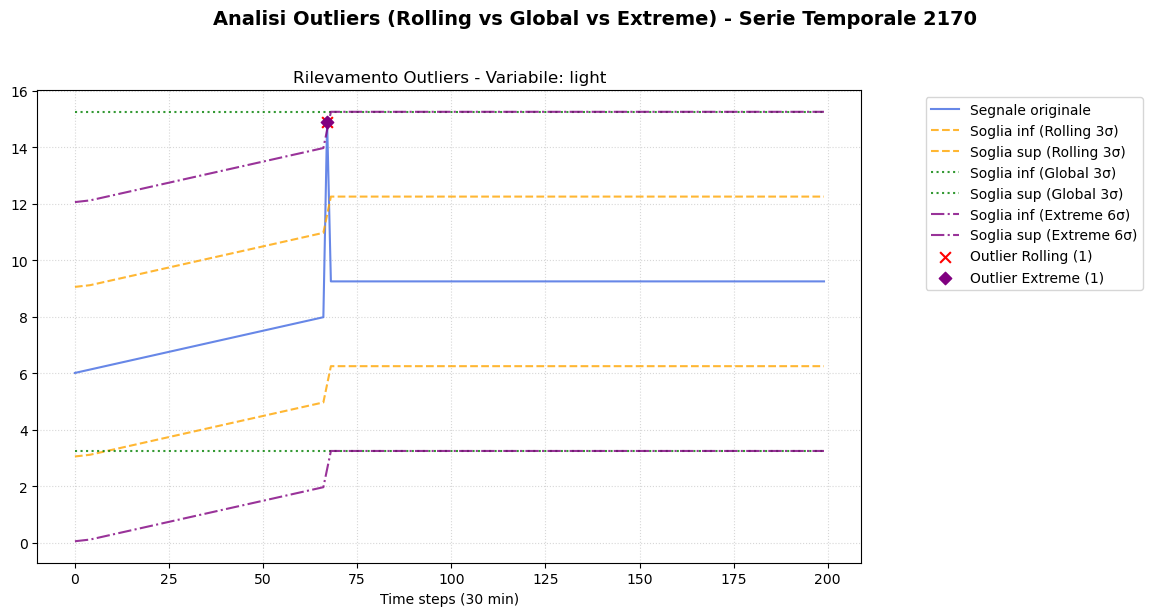

In [24]:
# Seleziona una serie temporale casuale che contenga possibilmente almeno un outlier per la visualizzazione
indice_esempio = random.randint(0, len(ts) - 1)
df_esempio = ts[indice_esempio]

# Rilevamento outliers (Rolling, Global, Extreme)
outliers_mask_rolling, bounds_rolling = rileva_outliers_hampel_rolling(df_esempio, colonne_hampel)
outliers_mask_global, bounds_global = rileva_outliers_hampel_global(df_esempio, colonne_hampel)
outliers_mask_extreme, bounds_extreme = rileva_outliers_hampel_rolling(df_esempio, colonne_hampel, n_sigmas=6)

# Visualizziamo enmo e light come variabili rappresentative
variabili_plot = ['light']
fig, axes = plt.subplots(len(variabili_plot), 1, figsize=(12, 6), sharex=True)

import numpy as np
axes = [axes] if len(variabili_plot) == 1 else axes
for ax, col in zip(axes, variabili_plot):
    # Plot del segnale originale
    ax.plot(df_esempio.index, df_esempio[col], label='Segnale originale', color='royalblue', alpha=0.8)
    
    # Plot dei limiti del filtro di Hampel (Rolling standard 3σ)
    lower_b_r, upper_b_r = bounds_rolling[col]
    ax.plot(df_esempio.index, lower_b_r, linestyle='--', color='orange', alpha=0.8, label='Soglia inf (Rolling 3σ)')
    ax.plot(df_esempio.index, upper_b_r, linestyle='--', color='orange', alpha=0.8, label='Soglia sup (Rolling 3σ)')
    
    # Plot dei limiti del filtro di Hampel (Global 3σ)
    lower_b_g, upper_b_g = bounds_global[col]
    ax.plot(df_esempio.index, np.full(len(df_esempio), lower_b_g), linestyle=':', color='green', alpha=0.8, label='Soglia inf (Global 3σ)')
    ax.plot(df_esempio.index, np.full(len(df_esempio), upper_b_g), linestyle=':', color='green', alpha=0.8, label='Soglia sup (Global 3σ)')
    
    # Plot dei limiti del filtro di Hampel (Extreme 6σ)
    lower_b_e, upper_b_e = bounds_extreme[col]
    ax.plot(df_esempio.index, lower_b_e, linestyle='-.', color='purple', alpha=0.8, label='Soglia inf (Extreme 6σ)')
    ax.plot(df_esempio.index, upper_b_e, linestyle='-.', color='purple', alpha=0.8, label='Soglia sup (Extreme 6σ)')
    
    # Evidenziazione degli outlier rilevati (Rolling standard)
    outlier_points_r = df_esempio[col][outliers_mask_rolling[col]]
    if len(outlier_points_r) > 0:
        ax.scatter(outlier_points_r.index, outlier_points_r, color='red', marker='x', s=60, zorder=5, 
                   label=f'Outlier Rolling ({len(outlier_points_r)})')
        
    # Evidenziazione degli outlier rilevati (Extreme)
    outlier_points_e = df_esempio[col][outliers_mask_extreme[col]]
    if len(outlier_points_e) > 0:
        ax.scatter(outlier_points_e.index, outlier_points_e, color='purple', marker='D', s=40, zorder=6, 
                   label=f'Outlier Extreme ({len(outlier_points_e)})')

    ax.set_title(f"Rilevamento Outliers - Variabile: {col}")
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1))
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle(f"Analisi Outliers (Rolling vs Global vs Extreme) - Serie Temporale {indice_esempio}", y=1.02, fontsize=14, fontweight='bold')
plt.xlabel("Time steps (30 min)")
plt.tight_layout()
plt.show()


## 6. Imputazione dei Dati Mancanti
Applichiamo l'interpolazione lineare locale sulle singole serie temporali per ripristinare i valori nulli creati dagli outlier, seguiti da forward e backward fill per eventuali outlier agli estremi.

In [25]:
ts_no_outliers_imputed = []
colonne_da_imputare = [col for col in ts_no_outliers[0].columns if col not in colonne_fisse]

def imputa_lista_ts(ts_list, colonne):
    ts_imputed_list = []
    for df in tqdm(ts_list, desc="Imputazione dati mancanti"):
        df_imputed = df.copy()
        df_imputed[colonne] = df_imputed[colonne].interpolate(method='linear').ffill().bfill()
        ts_imputed_list.append(df_imputed)
    return ts_imputed_list

print("Imputazione ts_no_outliers...")
ts_no_outliers_imputed = imputa_lista_ts(ts_no_outliers, colonne_da_imputare)
print(f"Imputazione completata: {len(ts_no_outliers_imputed)} serie temporali pronte.")

Imputazione ts_no_outliers...


Imputazione dati mancanti:   0%|          | 0/4437 [00:00<?, ?it/s]

Imputazione completata: 4437 serie temporali pronte.


## 7. Regolarizzazione della Luce (Trasformazione Logaritmica)
Applichiamo la trasformazione logaritmica `log1p` alla colonna `light` per gestirne la forte asimmetria (skewness) e stabilizzarne la varianza.

In [26]:
for df in ts_no_outliers_imputed:
    if 'light' in df.columns:
        df['light'] = np.log1p(df['light'])

## 8. Denoising tramite Media Mobile
Applichiamo una media mobile con finestra ridotta (`window=2`, ossia 1 ora reale di registrazione) per rimuovere il rumore ad alta frequenza lasciando inalterate le forme d'onda fisiologiche ad altezza elevata (fondamentali per rilevare gli *Shapelets*).

In [27]:
colonne_no_noise = colonne_fisse + ['non-wear_flag']
ts_denoised = []

for df in ts_no_outliers_imputed:
    df_pulito = df.copy()
    colonne_target = [col for col in df_pulito.columns if col not in colonne_no_noise]
    
    # Media mobile morbida
    df_pulito[colonne_target] = df_pulito[colonne_target].rolling(window=2, min_periods=1).mean()
    ts_denoised.append(df_pulito)

## 9. Normalizzazione e Creazione dei Dataset di Output
Normalizziamo le serie temporali seguendo due approcci distinti in base al tipo di analisi a valle:

1.  **Dati per Motifs/Shapelets (`ts_motifs_ready.pkl.gz`)**: Nessuna standardizzazione sulle accelerazioni (preserva le ampiezze fisiche, la standardizzazione locale z-score viene applicata dagli algoritmi a valle come Stumpy). Applichiamo solo MinMax globale su luce e batteria.
2.  **Dati per Classificazione/Clustering (`ts_datasetwise_normalized.pkl.gz`)**: Standardizzazione globale (*dataset-wise*) sulle variabili di movimento per non perdere le differenze relative di livello di attività tra bambini sedentari e attivi. MinMax globale su luce e batteria.

In [28]:
variabili_std = ['X', 'Y', 'Z', 'enmo', 'anglez']
variabili_minmax = ['battery_voltage', 'light']

# Fitting del MinMaxScaler globale su luce e batteria
minmax_scaler = MinMaxScaler()
dati_minmax_globali = pd.concat([df[variabili_minmax] for df in ts_denoised], ignore_index=True)
minmax_scaler.fit(dati_minmax_globali)

# 1. Creazione dataset per Motifs
ts_motifs_ready = []
for df in ts_denoised:
    df_norm = df.copy()
    df_norm[variabili_minmax] = minmax_scaler.transform(df_norm[variabili_minmax])
    ts_motifs_ready.append(df_norm)

with gzip.open("ts_motifs_ready.pkl.gz", "wb") as f:
    pickle.dump(ts_motifs_ready, f)
print("Salvato ts_motifs_ready.pkl.gz.")

Salvato ts_motifs_ready.pkl.gz.


In [29]:
# 2. Creazione dataset normalizzato globalmente (dataset-wise)
std_scaler_global = StandardScaler()
dati_std_globali = pd.concat([df[variabili_std] for df in ts_denoised], ignore_index=True)
std_scaler_global.fit(dati_std_globali)

ts_datasetwise_normalized = []
for df in ts_denoised:
    df_norm = df.copy()
    df_norm[variabili_std] = std_scaler_global.transform(df_norm[variabili_std])
    df_norm[variabili_minmax] = minmax_scaler.transform(df_norm[variabili_minmax])
    ts_datasetwise_normalized.append(df_norm)

with gzip.open("ts_datasetwise_normalized.pkl.gz", "wb") as f:
    pickle.dump(ts_datasetwise_normalized, f)
print("Salvato ts_datasetwise_normalized.pkl.gz.")

Salvato ts_datasetwise_normalized.pkl.gz.


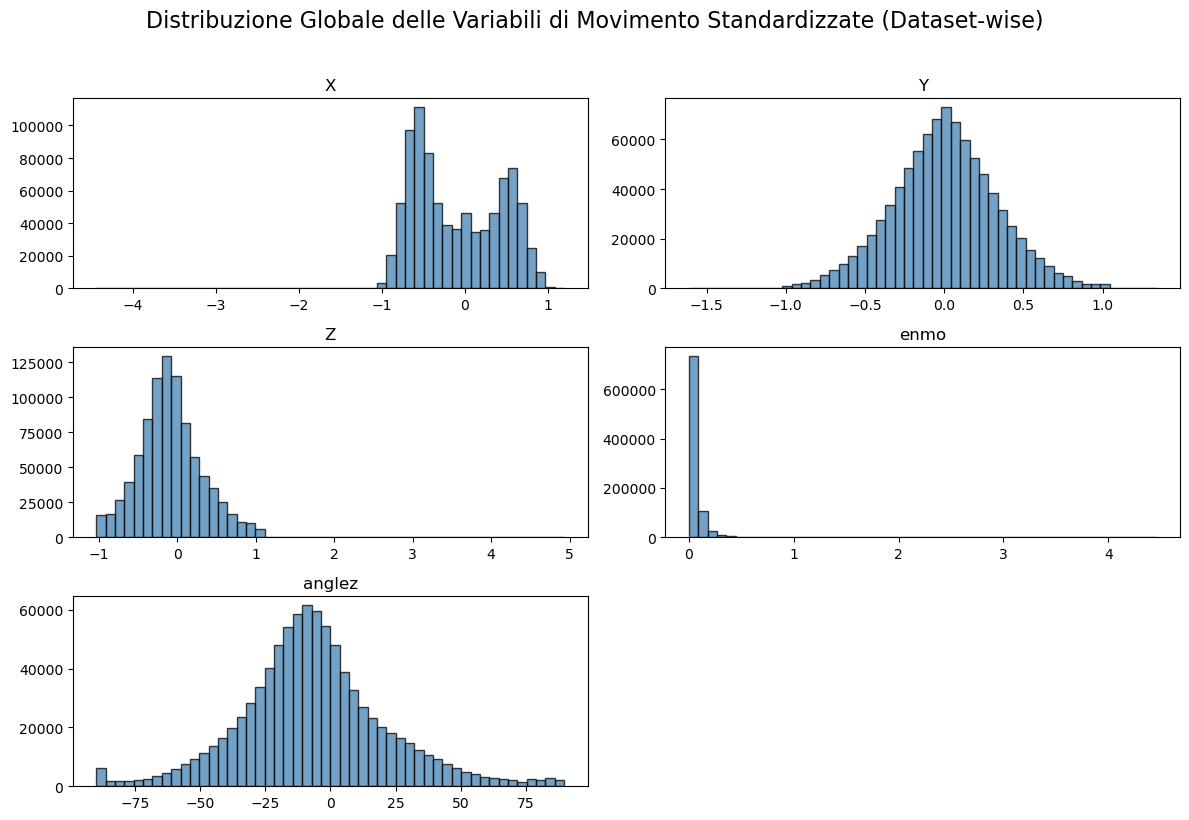

In [30]:
# Visualizzazione istogramma delle distribuzioni globali
df_plot = dati_std_globali.sample(frac=1.0, random_state=222)
df_plot.hist(bins=50, figsize=(12, 8), edgecolor='black', grid=False, alpha=0.75, color='steelblue')
plt.suptitle("Distribuzione Globale delle Variabili di Movimento Standardizzate (Dataset-wise)", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## 10. Approssimazione Temporale (PAA e SAX)
Applichiamo Piecewise Aggregate Approximation (PAA) e Symbolic Aggregate Approximation (SAX) per ridurre la granularità delle serie temporali da 200 passi temporali a 20 segmenti.

> [!IMPORTANT]
> **Integrità dei Metadati**: Per evitare di perdere gli identificatori degli utenti (`id`) e le label target (`sii_binary`), applichiamo PAA/SAX **solamente ai segnali fisici**. I metadati statici originali vengono ri-appesi intatti dopo la trasformazione.

In [31]:
# 1. Definizione colonne
colonne_segnali = ['X', 'Y', 'Z', 'enmo', 'anglez', 'light', 'battery_voltage']
colonne_metadata = ['id', 'sii_binary', 'weekday', 'quarter', 'relative_date_PCIAT']

# Estrazione dei soli segnali in formato 3D (n_ts, n_timesteps, n_features)
dati_segnali = np.array([df[colonne_segnali].values for df in ts_datasetwise_normalized])

# Applicazione di PAA
paa = PAA(n_segments=20)
segnali_paa = paa.fit_transform(dati_segnali)

# Ricostruzione mantenendo i metadati intatti
ts_transformed_paa = []
for i, df_originale in enumerate(ts_datasetwise_normalized):
    df_approssimato = pd.DataFrame(segnali_paa[i], columns=colonne_segnali)
    for col in colonne_metadata:
        df_approssimato[col] = df_originale[col].iloc[0]
    ts_transformed_paa.append(df_approssimato)

with gzip.open("ts_transformed_paa.pkl.gz", "wb") as f:
    pickle.dump(ts_transformed_paa, f)
print(f"Salvato ts_transformed_paa.pkl.gz (segmenti: {ts_transformed_paa[0].shape[0]}, colonne: {ts_transformed_paa[0].shape[1]}).")

Salvato ts_transformed_paa.pkl.gz (segmenti: 20, colonne: 12).


In [32]:
# 2. Applicazione di SAX
sax = SAX(n_segments=20, alphabet_size_avg=5)
segnali_sax = sax.fit_transform(dati_segnali)

# Ricostruzione mantenendo i metadati intatti
ts_transformed_sax = []
for i, df_originale in enumerate(ts_datasetwise_normalized):
    df_sax = pd.DataFrame(segnali_sax[i], columns=colonne_segnali)
    for col in colonne_metadata:
        df_sax[col] = df_originale[col].iloc[0]
    ts_transformed_sax.append(df_sax)

with gzip.open("ts_transformed_sax.pkl.gz", "wb") as f:
    pickle.dump(ts_transformed_sax, f)
print(f"Salvato ts_transformed_sax.pkl.gz (segmenti: {ts_transformed_sax[0].shape[0]}, colonne: {ts_transformed_sax[0].shape[1]}).")

Salvato ts_transformed_sax.pkl.gz (segmenti: 20, colonne: 12).


## 11. Confronto dei Grafici
Visualizziamo l'effetto finale del preprocessing confrontando i grafici originali con quelli puliti, denoised, normalizzati e approssimati per un singolo soggetto campionato a caso.

=== TIME SERIES DEL SOGGETTO ALLA POSIZIONE 334 ===


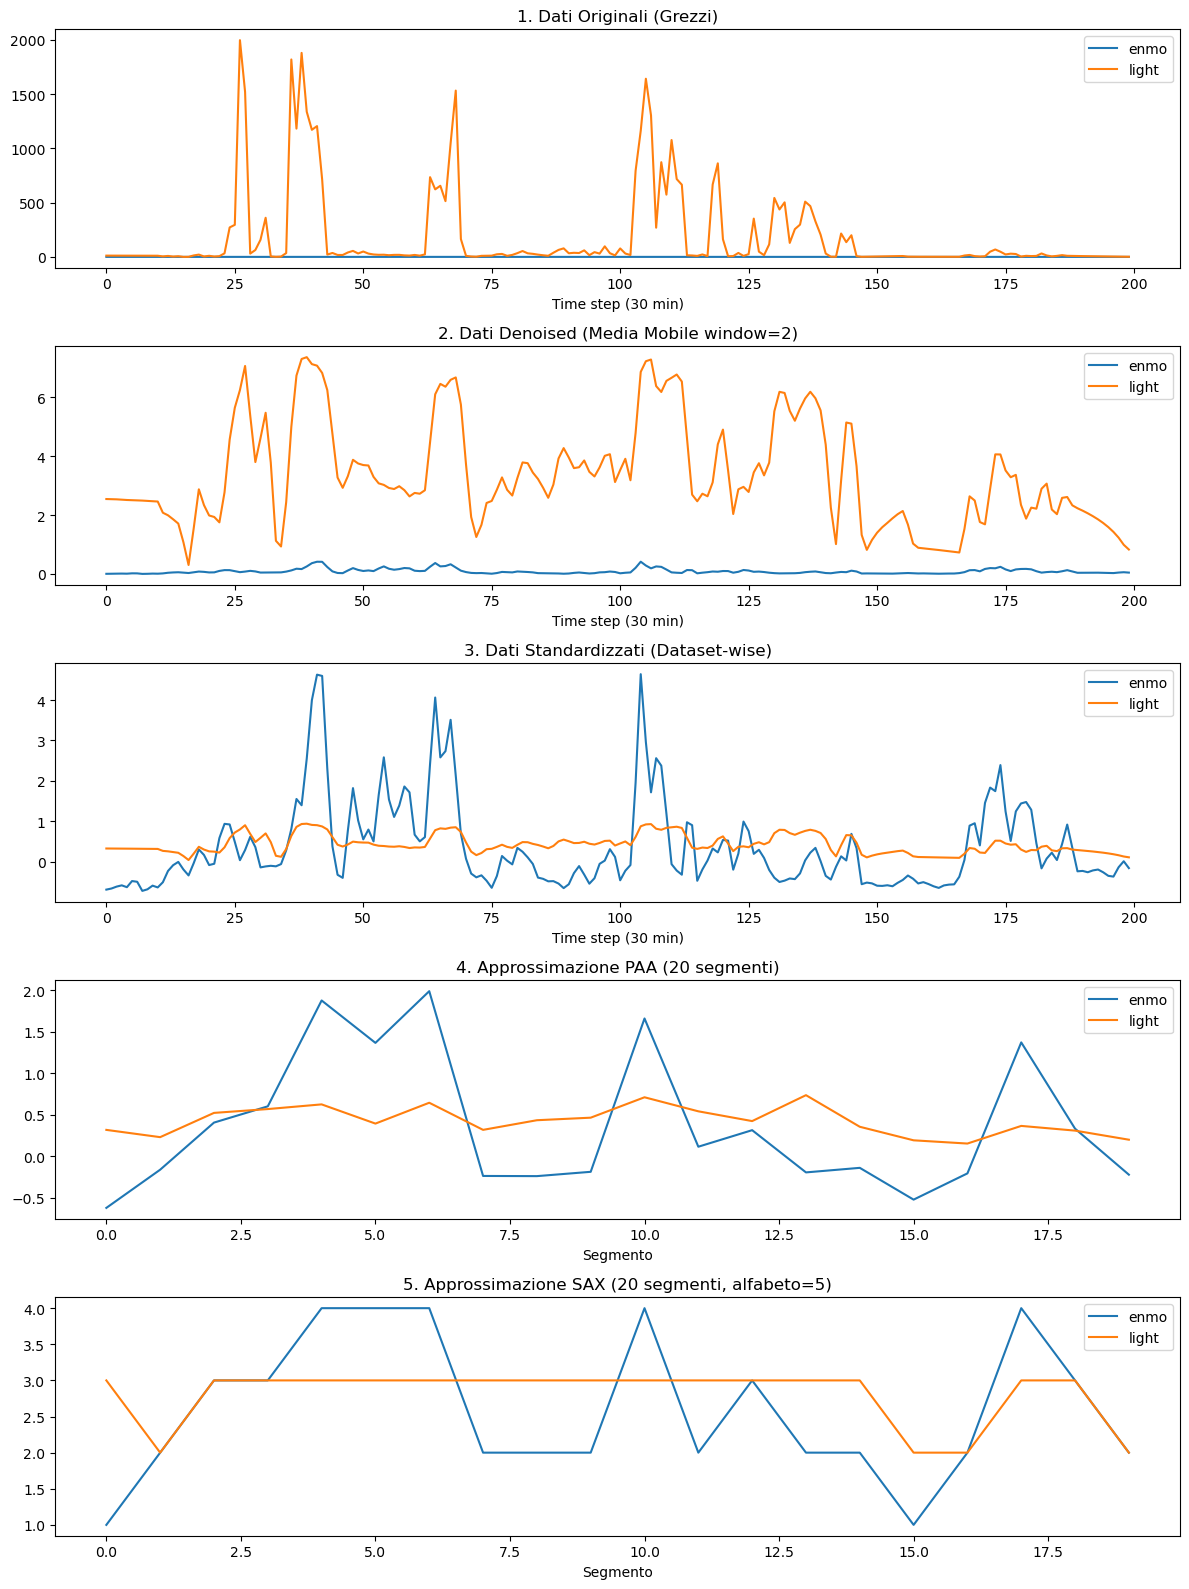

In [33]:
indice = random.randint(0, len(ts) - 1)

print(f"=== TIME SERIES DEL SOGGETTO ALLA POSIZIONE {indice} ===")
fig, axes = plt.subplots(5, 1, figsize=(12, 16), sharex=False)

# 1. Originale
ts[indice][['enmo', 'light']].plot(ax=axes[0], title="1. Dati Originali (Grezzi)")
axes[0].set_xlabel("Time step (30 min)")

# 2. Denoised
ts_denoised[indice][['enmo', 'light']].plot(ax=axes[1], title="2. Dati Denoised (Media Mobile window=2)")
axes[1].set_xlabel("Time step (30 min)")

# 3. Normalizzato
ts_datasetwise_normalized[indice][['enmo', 'light']].plot(ax=axes[2], title="3. Dati Standardizzati (Dataset-wise)")
axes[2].set_xlabel("Time step (30 min)")

# 4. PAA
ts_transformed_paa[indice][['enmo', 'light']].plot(ax=axes[3], title="4. Approssimazione PAA (20 segmenti)")
axes[3].set_xlabel("Segmento")

# 5. SAX
ts_transformed_sax[indice][['enmo', 'light']].plot(ax=axes[4], title="5. Approssimazione SAX (20 segmenti, alfabeto=5)")
axes[4].set_xlabel("Segmento")

plt.tight_layout()
plt.show()